<a href="https://colab.research.google.com/github/1824034QM/1824034QM/blob/main/Unit2(a).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

State n=1:
Numerical E= 4.8955
Analytical E= 4.9348

State n=2:
Numerical E= 19.5817
Analytical E= 19.7392

State n=3:
Numerical E= 44.0580
Analytical E= 44.4132



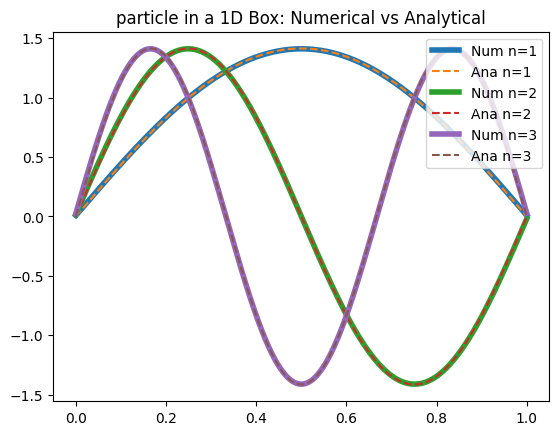

In [1]:


import numpy as np
import matplotlib.pyplot as plt

# Box Parameters (hbar=1, m=1)
L=1
N=500
x=np.linspace(0,L,N)
dx=x[1]-x[0]

main_diag=2*np.ones(N)
off_diag=-1*np.ones(N-1)

# Hamiltonian H= (-hbar²/2m dx²)*matrix
H= (1/(2*dx**2))*(np.diag(main_diag)+np.diag(off_diag,1)+np.diag(off_diag,-1))

energies, wavefunctions= np.linalg.eigh(H)

# Compare with analytical formulas and plot the first 3 states(n=1,2,3)
for n in range(1,4):
    E_ana= (n**2*np.pi**2)/(2*L**2)
    E_num= energies[n-1]

    print(f'State n={n}:')
    print(f'Numerical E= {E_num:.4f}')
    print(f'Analytical E= {E_ana:.4f}\n')

    psi_num= wavefunctions[:, n-1]
    psi_num /= np.sqrt(np.sum(psi_num**2)*dx)

    psi_ana= np.sqrt(2/L)*np.sin(n*np.pi*x/L)

    #(optical fix) matrices sometimes return the wave upside down
    if psi_num[10]*psi_ana[10]<0:
        psi_num= -psi_num

    plt.plot(x, psi_num, linewidth=4, label=f'Num n={n}')
    plt.plot(x, psi_ana, '--', label=f'Ana n={n}') #white dashed line to prove overlap

plt.title('particle in a 1D Box: Numerical vs Analytical')
plt.legend(loc='upper right')
plt.show()